# Shared setup and data loading

This notebook uses the **incident-level cleaned dataset**. Each row should represent one unique `Incident ID`, not one offence record. Multi-valued offence fields are stored as strings separated by ` | `.

The analysis is descriptive and exploratory, in line with the CI7340 brief. The coursework requires 10 research questions and 20 question-linked visualisations overall; this notebook contributes two visualisations to its assigned research question.

**Input:** `crime_dataset_incident_level_cleaned.csv`

> Run the notebook from top to bottom. Keep the original cleaned dataset unchanged.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from collections import Counter
from scipy.stats import chi2_contingency, spearmanr, kruskal
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["figure.dpi"] = 120

In [2]:
df = pd.read_csv("crime_dataset_incident_level_cleaned.csv", low_memory=False)

In [3]:
print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns):,}")
print(f"Unique Incident IDs: {df['Incident ID'].nunique():,}")
print(f"Duplicate Incident IDs: {df['Incident ID'].duplicated().sum():,}")

Rows: 467,601
Columns: 50
Unique Incident IDs: 467,601
Duplicate Incident IDs: 0


## Data integrity check

The incident-level unit of analysis is essential here. The following check confirms that each `Incident ID` appears once. If duplicate IDs are found, stop and resolve the issue rather than silently dropping rows.

In [4]:
assert df["Incident ID"].is_unique, (
    "Incident ID is not unique. This file is not one-row-per-incident."
)

## Parse multi-valued fields

During incident-level aggregation, offence labels were retained as pipe-separated unique values. This helper converts those strings into lists and removes empty or duplicate labels. It supports both single-offence and multi-offence incidents.

In [5]:
def split_multi_value(value):
    if pd.isna(value):
        return []
    return list(dict.fromkeys(
        item.strip() for item in str(value).split("|") if item.strip()
    ))

# H2 — Crime-category composition in single- and multi-offence incidents

## Research question

**Do multi-offence incidents contain different crime-category compositions compared with single-offence incidents?**

### Analytical framing
- **Unit of analysis:** one unique `Incident ID`.
- **Explanatory variable (X):** incident type — single-offence (`Total_Offence_Records == 1`) or multi-offence (`> 1`).
- **Outcome (Y):** presence and composition of crime categories recorded within each incident.
- **Expected evidence:** category membership rates and category composition by incident type.

The dataset's `Crime Name1` field can contain multiple pipe-separated values for multi-offence incidents. It must be split before comparing category membership. Since one incident may contain more than one broad category, percentages in the category-membership chart are not expected to sum to 100%.

## 1. Prepare incident groups and category membership

The supplied incident-level field `Total_Offence_Records` defines the single/multiple distinction. This is preferable to inferring it from a row count after the data has already been aggregated.

In [6]:
required = ["Incident ID", "Crime Name1", "Crime Name2", "Total_Offence_Records"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Missing required columns: {missing}")

In [7]:
df["Incident_Type"] = np.where(
    df["Total_Offence_Records"].gt(1),
    "Multi-offence",
    "Single-offence"
)

In [8]:
df["crime_categories"] = df["Crime Name1"].apply(split_multi_value)

In [9]:
group_summary = (
    df.groupby("Incident_Type")
    .agg(
        Incident_Count=("Incident ID", "nunique"),
        Mean_Offence_Records=("Total_Offence_Records", "mean"),
        Median_Offence_Records=("Total_Offence_Records", "median")
    )
    .reindex(["Single-offence", "Multi-offence"])
)
display(group_summary)

,Incident_Count,Mean_Offence_Records,Median_Offence_Records
Incident_Type,,,
Single-offence,433852,1.000000,1.0
Multi-offence,33749,2.200184,2.0


## 2. Calculate category membership rates

For each broad NIBRS crime category, calculate the percentage of incidents in each group that contain that category at least once. The denominator is the number of incidents in the corresponding single/multi group. Deduplication within an incident prevents a category from being counted more than once for the same incident.

In [10]:
membership = (
    df[["Incident ID", "Incident_Type", "crime_categories"]]
    .explode("crime_categories")
    .dropna(subset=["crime_categories"])
    .drop_duplicates(["Incident ID", "crime_categories"])
)

In [11]:
membership_counts = (
    membership.groupby(["Incident_Type", "crime_categories"])["Incident ID"]
    .nunique()
    .rename("Incident_Count")
    .reset_index()
)

In [12]:
group_denominators = df.groupby("Incident_Type")["Incident ID"].nunique()
membership_counts["Group_Total"] = membership_counts["Incident_Type"].map(group_denominators)
membership_counts["Percentage"] = (
    membership_counts["Incident_Count"] / membership_counts["Group_Total"] * 100
)
display(membership_counts.sort_values(["crime_categories", "Incident_Type"]))

,Incident_Type,crime_categories,Incident_Count,Group_Total,Percentage
0,Multi-offence,Crime Against Not a Crime,146,33749,0.432605
4,Single-offence,Crime Against Not a Crime,6012,433852,1.385726
1,Multi-offence,Crime Against Person,9186,33749,27.218584
5,Single-offence,Crime Against Person,42404,433852,9.773840
2,Multi-offence,Crime Against Property,20498,33749,60.736614
6,Single-offence,Crime Against Property,212477,433852,48.974535
3,Multi-offence,Crime Against Society,16774,33749,49.702213
7,Single-offence,Crime Against Society,172959,433852,39.865899


## Descriptive comparison

The table below presents category membership as a percentage within each incident group. This is a fairer comparison than raw counts because single-offence incidents are much more numerous than multi-offence incidents.

In [13]:
membership_pivot = membership_counts.pivot(
    index="crime_categories", columns="Incident_Type", values="Percentage"
).fillna(0)
display(membership_pivot.sort_values("Multi-offence", ascending=False))

Incident_Type,Multi-offence,Single-offence
crime_categories,,
Crime Against Property,60.736614,48.974535
Crime Against Society,49.702213,39.865899
Crime Against Person,27.218584,9.773840
Crime Against Not a Crime,0.432605,1.385726


## Visualisation 1 — Broad crime-category membership by incident type

A grouped horizontal bar chart compares the percentage of single-offence and multi-offence incidents containing each broad category. Percentages use the relevant group size as the denominator. Categories can overlap within multi-offence incidents, so bars are not parts of a single 100% total.

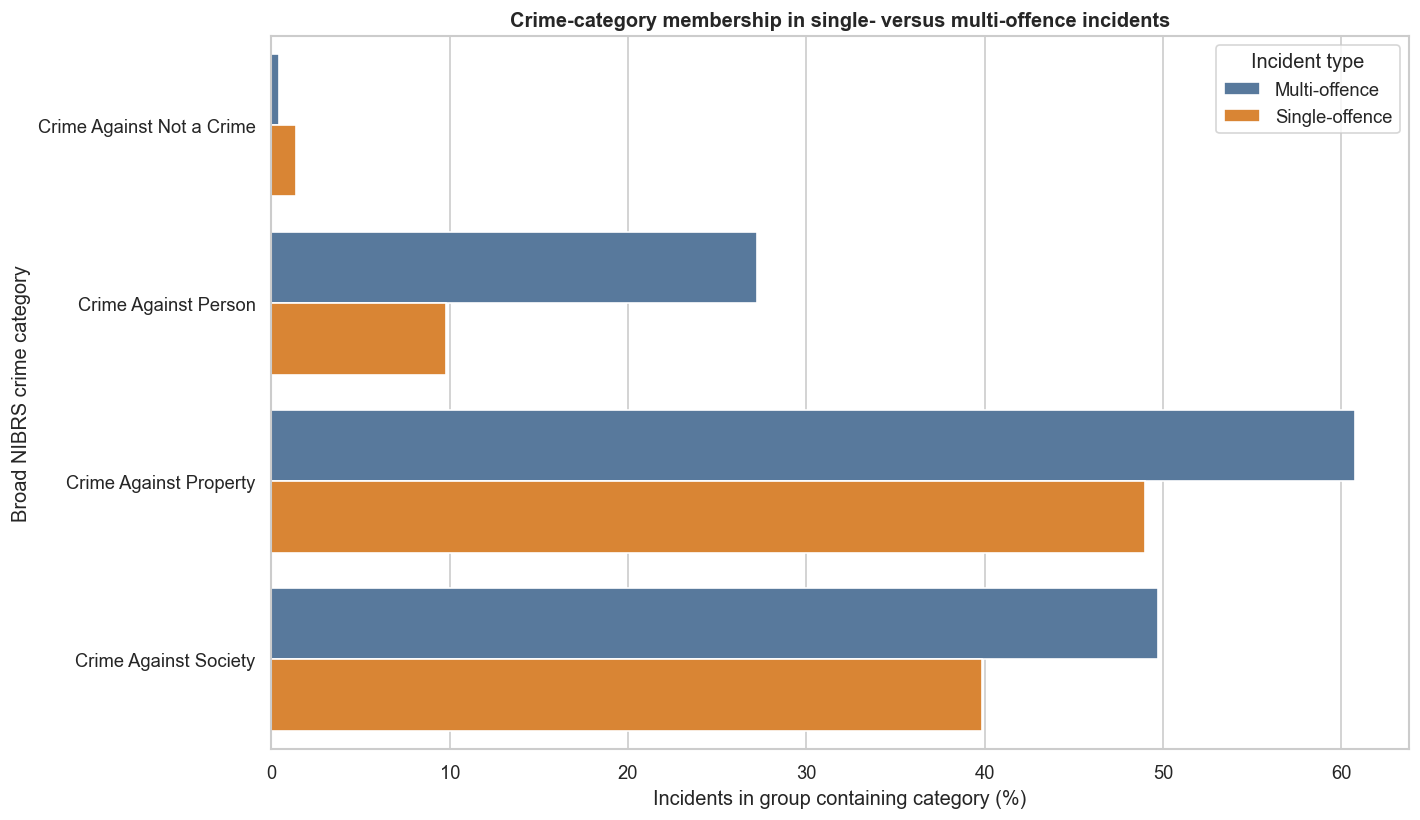

In [14]:
plot_membership = membership_pivot.reset_index().melt(
    id_vars="crime_categories",
    var_name="Incident type",
    value_name="Incidents containing category (%)"
)
fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(
    data=plot_membership,
    y="crime_categories",
    x="Incidents containing category (%)",
    hue="Incident type",
    palette=["#4C78A8", "#F58518"],
    ax=ax
)
ax.set_title("Crime-category membership in single- versus multi-offence incidents", weight="bold")
ax.set_xlabel("Incidents in group containing category (%)")
ax.set_ylabel("Broad NIBRS crime category")
ax.legend(title="Incident type")
plt.tight_layout()
plt.show()

**How to interpret Figure 1:** Identify categories with the largest percentage-point differences between the two groups. A higher membership rate in multi-offence incidents suggests that the category is more commonly represented in incidents that contain multiple offence records. It does not mean that the category itself caused additional offences.

## 3. Compare detailed offence-category composition

The second comparison uses `Crime Name2`, the more detailed NIBRS offence-name level. For readability, the plot includes the 12 most common labels across the dataset. The percentages again use each incident group as the denominator and represent the share of incidents containing each label.

In [15]:
df["nibrs_categories"] = df["Crime Name2"].apply(split_multi_value)
nibrs_membership = (
    df[["Incident ID", "Incident_Type", "nibrs_categories"]]
    .explode("nibrs_categories")
    .dropna(subset=["nibrs_categories"])
    .drop_duplicates(["Incident ID", "nibrs_categories"])
)

In [16]:
top_nibrs = (
    nibrs_membership["nibrs_categories"]
    .value_counts()
    .head(12)
    .index
)
nibrs_counts = (
    nibrs_membership[nibrs_membership["nibrs_categories"].isin(top_nibrs)]
    .groupby(["Incident_Type", "nibrs_categories"])["Incident ID"]
    .nunique()
    .rename("Incident_Count")
    .reset_index()
)
nibrs_counts["Group_Total"] = nibrs_counts["Incident_Type"].map(group_denominators)
nibrs_counts["Percentage"] = nibrs_counts["Incident_Count"] / nibrs_counts["Group_Total"] * 100

## Visualisation 2 — Detailed NIBRS offence composition by incident type

This heatmap displays the percentage of incidents in each group that contain each of the 12 most prevalent NIBRS offence labels. A heatmap is useful here because it allows several offence types and both incident groups to be compared in one compact figure.

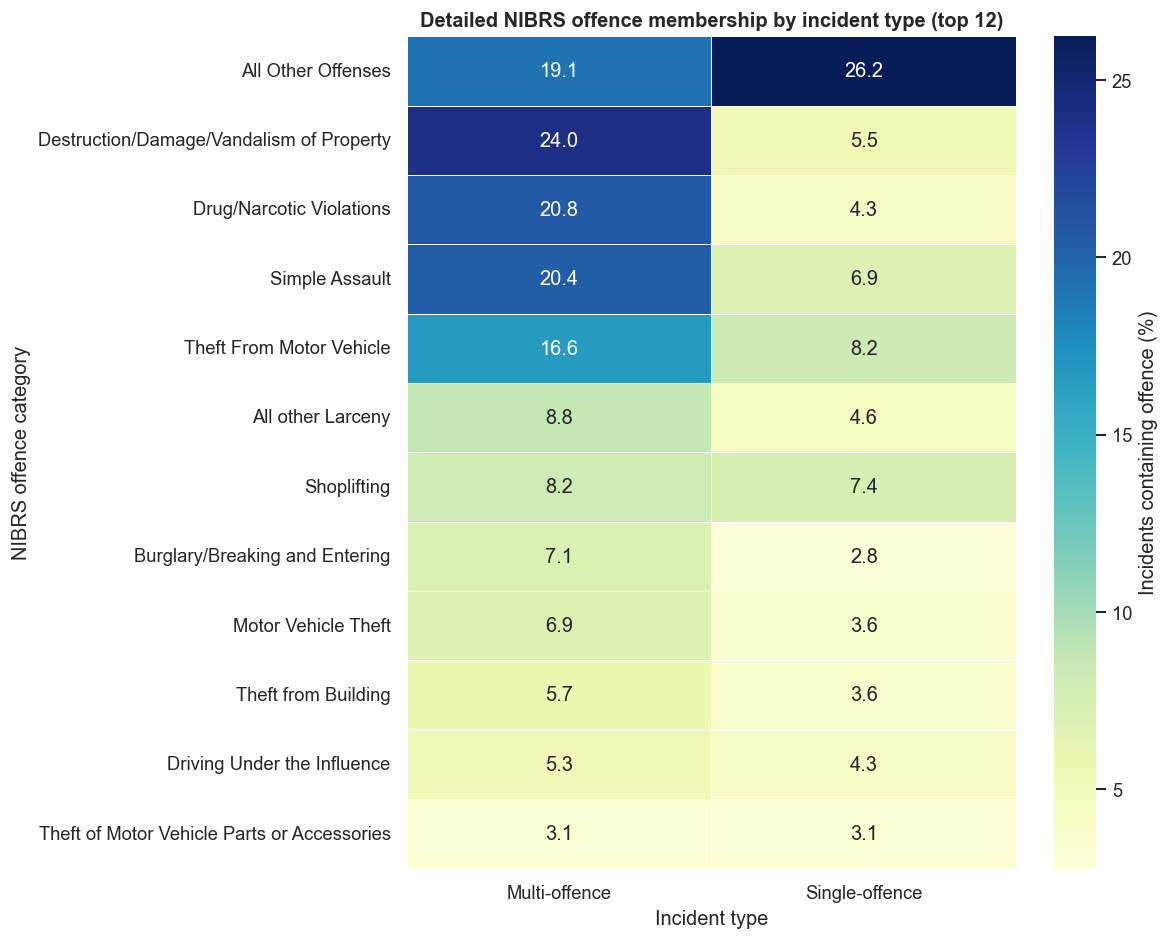

In [17]:
nibrs_heatmap = nibrs_counts.pivot(
    index="nibrs_categories",
    columns="Incident_Type",
    values="Percentage"
).fillna(0)
nibrs_heatmap = nibrs_heatmap.reindex(
    nibrs_heatmap.max(axis=1).sort_values(ascending=False).index
)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    nibrs_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Incidents containing offence (%)"},
    ax=ax
)
ax.set_title("Detailed NIBRS offence membership by incident type (top 12)", weight="bold")
ax.set_xlabel("Incident type")
ax.set_ylabel("NIBRS offence category")
plt.tight_layout()
plt.show()

**How to interpret Figure 2:** Compare the two columns for each offence label. Strong differences indicate that the detailed offence mix is not identical between single- and multi-offence incidents. Remember that the chart is based on category presence per incident, not on the number of offence rows.

## Optional association check: broad category membership

The chi-square tests below compare whether the presence/absence of each broad category is associated with incident type. They are supplementary descriptive checks, not a substitute for interpreting effect size. With a very large dataset, small differences can produce small p-values; therefore Cramér's V and percentage-point differences are more useful for judging practical magnitude.

Each category is tested separately as a 2×2 table. The tests are exploratory and do not establish causality.

In [18]:
test_rows = []
for category in sorted(membership["crime_categories"].unique()):
    present_ids = set(membership.loc[
        membership["crime_categories"].eq(category), "Incident ID"
    ])
    present = df["Incident ID"].isin(present_ids)
    table = pd.crosstab(df["Incident_Type"], present)
    if table.shape == (2, 2):
        chi2, p_value, dof, expected = chi2_contingency(table)
        n = table.to_numpy().sum()
        cramers_v = np.sqrt(chi2 / n) if n else np.nan
        test_rows.append({
            "Crime category": category,
            "Chi-square": chi2,
            "p-value": p_value,
            "Cramer's V": cramers_v
        })
category_tests = pd.DataFrame(test_rows).sort_values("Cramer's V", ascending=False)
display(category_tests)

,Crime category,Chi-square,p-value,Cramer's V
1,Crime Against Person,9706.380480,0.000000e+00,0.144076
2,Crime Against Property,1732.378443,0.000000e+00,0.060867
3,Crime Against Society,1256.088756,3.943457e-275,0.051829
0,Crime Against Not a Crime,218.152167,2.287972e-49,0.021599


## Conclusion and limitations

Answer the research question by referring to both figures and the percentage table.

- The first visualisation compares broad crime-category membership.
- The second visualisation identifies which detailed NIBRS offence labels distinguish the groups.
- Single-offence incidents form the much larger group, so compare percentages rather than raw counts.
- One multi-offence incident may contain multiple broad and detailed categories; category membership percentages therefore need not sum to 100%.
- The dataset contains reported, founded police incidents, not all crime occurring in the county.
- Association tests can be statistically significant because of the large sample size. Discuss Cramér's V and the size of observed differences.

**Suggested reporting sentence:** “Compared with single-offence incidents, multi-offence incidents showed a higher/lower membership rate for … . The detailed NIBRS heatmap further indicated … .”